# GRAZPEDWRI-DX · Dataset EDA

Pregled celog lokalnog CSV/YOLO izvoza i inventara slika. Jedinice analize su CSV red, slika, pacijent i anotirani objekat.

## 1. Poreklo i struktura

**Istraživačko pitanje.** Koji izvori ulaze u analizu?

**Postupak.** Čitamo CSV, izvorni YOLO izvoz i direktorijume četiri ZIP arhive. Evidencija porekla i SHA-256 otisci identifikuju CSV i anotacije.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display, Markdown

from wrist_fracture.data.eda import link_annotations, missing_table, source_fingerprint
from wrist_fracture.data.eda_settings import (
    DATASET, SEED, USE_CACHE, analytical_images, load_inputs, stratified_examples,
)
from wrist_fracture.visualization.image_eda import show_gallery_pages

sns.set_theme(style='whitegrid', palette='deep', rc={
    'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.precision', 4)
root, csv_path, annotation_path, metadata, audit, index, index_issues = load_inputs()
linked = link_annotations(metadata, audit)
images = analytical_images(metadata, audit, index)
expected = set(metadata.filestem.dropna())
indexed = set(index.filestem)
valid_boxes = audit.boxes.loc[audit.boxes.valid]

def summary(**values):
    display(Markdown('**Numerički sažetak**'))
    display(pd.Series(values, name='vrednost').to_frame())

def plot(fig):
    fig.tight_layout()
    plt.show()
    plt.close(fig)

from importlib.metadata import version
import json
import platform

display(pd.DataFrame([source_fingerprint(csv_path), source_fingerprint(annotation_path)]))
records = [json.loads(path.read_text(encoding='utf-8'))
           for path in sorted((csv_path.parent / '.provenance').glob('*.json'))]
display(pd.DataFrame([{
    'fajl': row.get('file', {}).get('name'),
    'Figshare članak': row.get('article', {}).get('id'),
    'verzija': row.get('article', {}).get('version'),
    'MD5 potvrđen pri preuzimanju': row.get('verification', {}).get('source_md5_verified'),
} for row in records]))
display(pd.Series({'Python': platform.python_version(), **{
    package: version(package) for package in ['pandas', 'numpy', 'matplotlib', 'seaborn', 'PyYAML']}},
    name='verzija').to_frame())
summary(izvor=DATASET, CSV_redovi=len(metadata), atributi=metadata.shape[1],
        lokalni_zapisi_porekla=len(records), indeksirane_arhive=index.source.nunique())

,file,bytes,sha256
0,dataset.csv,1850724,55a53cbe9673e5f29ef0f2f6074ae791f1c27a3b48efad...
1,folder_structure.zip,26304897,eac47bc5dfc01c1487289df53fc6bbfbfefd2e4a3bbcde...


,fajl,Figshare članak,verzija,MD5 potvrđen pri preuzimanju
0,images_part3.zip,14825193,2,True
1,dataset.csv,14825193,2,True
2,images_part4.zip,14825193,2,True
3,images_part1.zip,14825193,2,True
4,images_part2.zip,14825193,2,True
5,images_part1.zip,14825193,2,True
6,folder_structure.zip,14825193,2,True


,verzija
Python,3.13.2
pandas,3.0.3
numpy,2.5.1
matplotlib,3.11.1
seaborn,0.13.2
PyYAML,6.0.2


**Numerički sažetak**

,vrednost
izvor,GRAZPEDWRI-DX v2
CSV_redovi,20327
atributi,17
lokalni_zapisi_porekla,7
indeksirane_arhive,4


## 2. CSV šema, identifikatori i praznine


,tip,jedinstvene poznate vrednosti,missing,percent
filestem,string,20327,0,0.0000
patient_id,string,6091,0,0.0000
study_number,string,12,0,0.0000
timehash,string,20325,0,0.0000
gender,str,3,0,0.0000
age,float64,187,0,0.0000
laterality,str,2,0,0.0000
projection,int64,3,0,0.0000
initial_exam,float64,1,9466,46.5686
ao_classification,str,107,6169,30.3488


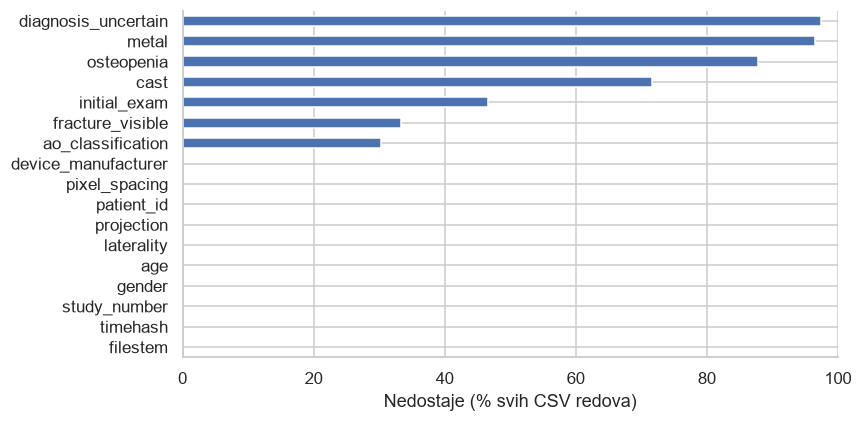

**Numerički sažetak**

,vrednost
CSV_redovi,20327
CSV_duplirani_redovi,0
prazni_filestem,0
neispravni_identifikatori,0
kolone_sa_prazninama,7
najviše_praznina,diagnosis_uncertain (97.36%)


In [2]:
missing = missing_table(metadata)
display(pd.DataFrame({'tip': metadata.dtypes.astype(str),
                      'jedinstvene poznate vrednosti': metadata.nunique()}).join(missing))
fig, ax = plt.subplots(figsize=(8, 4))
missing.percent.sort_values().plot.barh(ax=ax)
ax.set(xlabel='Nedostaje (% svih CSV redova)', ylabel='', xlim=(0, 100))
plot(fig)
summary(CSV_redovi=len(metadata), CSV_duplirani_redovi=int(metadata.filestem.duplicated(keep=False).sum()),
        prazni_filestem=int(metadata.filestem.isna().sum()),
        neispravni_identifikatori=int(linked.annotation_state.eq('invalid_identifier').sum()),
        kolone_sa_prazninama=int(missing.missing.gt(0).sum()),
        najviše_praznina=f'{missing.index[0]} ({missing.percent.iloc[0]:.2f}%)')

### Zaključak

Skup podataka sadrži 20.327 zapisa, bez dupliranih redova, praznih ili neispravnih identifikatora.

Nedostajuće vrednosti prisutne su u 7 kolona, prvenstveno u atributima koji opisuju specifična medicinska stanja i karakteristike snimaka. Njihovo odsustvo ne mora nužno predstavljati problem kvaliteta podataka, već može biti posledica načina evidentiranja medicinskih informacija.

S obzirom na to da je cilj projekta detekcija preloma pomoću YOLO modela, nedostajuće vrednosti u metapodacima nisu direktna prepreka za treniranje, jer su za njega prvenstveno važni ispravni snimci i odgovarajuće anotacije.

## 3. Pacijenti i identifikatori studija


,count,mean,std,min,25%,50%,75%,max
snimci,6091.0,3.3372,2.5336,1.0,2.0,2.0,4.0,30.0
različiti study_number,6091.0,1.7565,1.3408,1.0,1.0,1.0,2.0,12.0


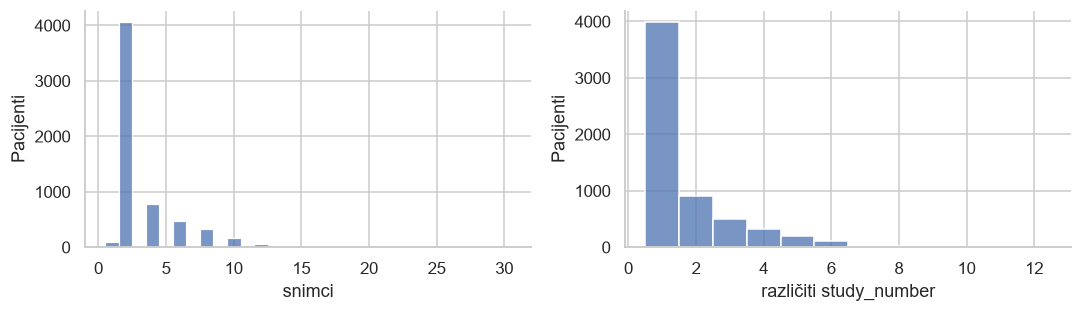

**Numerički sažetak**

,vrednost
pacijenti,6091.0
parovi_pacijent_study_number,10699.0
medijana_slika_po_pacijentu,2.0
min_slika,1.0
max_slika,30.0


In [3]:
patients = metadata.dropna(subset=['patient_id']).groupby('patient_id')
per_patient = patients.size().rename('snimci')
study_counts = patients.study_number.nunique().rename('različiti study_number')
study_pairs = int(study_counts.sum())
display(pd.concat([per_patient, study_counts], axis=1).describe().T)
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
sns.histplot(per_patient, discrete=True, ax=axes[0])
sns.histplot(study_counts, discrete=True, ax=axes[1])
for ax, label in zip(axes, [per_patient.name, study_counts.name]):
    ax.set(xlabel=label, ylabel='Pacijenti')
plot(fig)
summary(pacijenti=len(per_patient), parovi_pacijent_study_number=study_pairs,
        medijana_slika_po_pacijentu=float(per_patient.median()),
        min_slika=int(per_patient.min()), max_slika=int(per_patient.max()))

### Zaključak

Skup podataka obuhvata 6.091 pacijenta i 10.699 različitih parova pacijent–pregled. Prosečan broj snimaka po pacijentu iznosi 3,34, dok je medijana 2. Raspodela je asimetrična udesno, što ukazuje na to da većina pacijenata ima mali broj snimaka, dok pojedini imaju i do 30.

Prisustvo više snimaka istog pacijenta posebno je važno prilikom podele podataka. Kako bi se sprečio **data leakage**, podelu na trening, validacioni i test skup potrebno je izvršiti na nivou pacijenta, a ne pojedinačnih snimaka.

## 4. Demografija



,po slici,minimum po pacijentu
count,20327.0000,6091.0000
mean,10.9202,10.8220
std,3.6053,3.7761
min,0.2000,0.2000
25%,8.5000,8.4000
50%,11.2000,11.2000
75%,13.6000,13.6000
max,19.0000,19.0000


,slike,pacijenti
gender,,
M,12040,3401
F,8285,2689
O,2,1


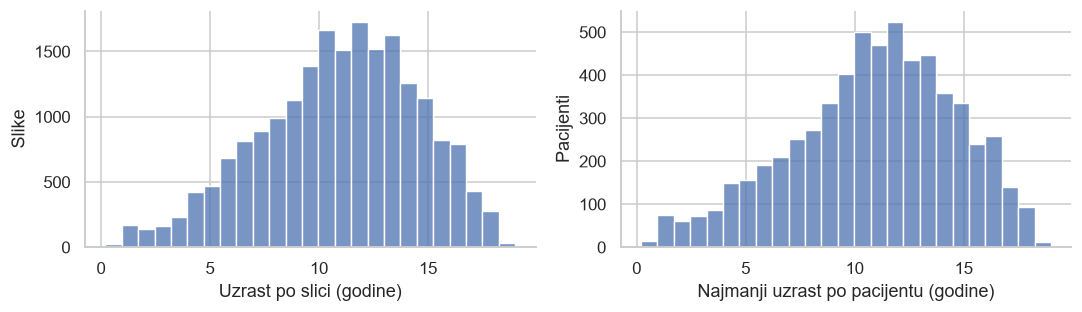

**Numerički sažetak**

,vrednost
slike_sa_uzrastom,20327.00
pacijenti_sa_uzrastom,6091.00
srednji_uzrast_po_slici,10.92
srednji_minimum_po_pacijentu,10.82
pacijenti_sa_konfliktom_pola,0.00


In [4]:
patient_age = patients.age.min()
patient_gender = patients.gender.agg(
    lambda s: s.dropna().iloc[0] if s.nunique() == 1
    else ('nedostaje' if not s.nunique() else 'konflikt'))
display(pd.DataFrame({'po slici': metadata.age.describe(),
                      'minimum po pacijentu': patient_age.describe()}))
display(pd.concat([metadata.gender.value_counts(dropna=False).rename('slike'),
                   patient_gender.value_counts(dropna=False).rename('pacijenti')], axis=1))
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
sns.histplot(metadata.age, bins=25, ax=axes[0])
sns.histplot(patient_age, bins=25, ax=axes[1])
axes[0].set(xlabel='Uzrast po slici (godine)', ylabel='Slike')
axes[1].set(xlabel='Najmanji uzrast po pacijentu (godine)', ylabel='Pacijenti')
plot(fig)
summary(slike_sa_uzrastom=int(metadata.age.count()), pacijenti_sa_uzrastom=int(patient_age.count()),
        srednji_uzrast_po_slici=round(metadata.age.mean(), 2),
        srednji_minimum_po_pacijentu=round(patient_age.mean(), 2),
        pacijenti_sa_konfliktom_pola=int(patient_gender.eq('konflikt').sum()))

### Zaključak

Uzrast pacijenata kreće se od 0,2 do 19 godina, sa prosečnim uzrastom po snimku od 10,92 godine. Najzastupljeniji su pacijenti uzrasta između 10 i 14 godina, dok su najmlađi pacijenti slabije zastupljeni.

U skupu podataka više su zastupljeni pacijenti muškog pola (3.401) u odnosu na pacijente ženskog pola (2.689). Nisu pronađene nedoslednosti u evidentiranju pola istog pacijenta.

Razlike u zastupljenosti uzrasnih i polnih grupa treba uzeti u obzir prilikom podele podataka i interpretacije rezultata modela, jer mogu uticati na njegovu sposobnost generalizacije.

## 5. Projekcije, proizvođači i metapodaci pregleda

**Istraživačko pitanje.** Koliko su zastupljene izvorne kategorije snimanja?

**Postupak.** Brojimo projekciju, stranu, proizvođača i initial_exam po slici. Pixel spacing prikazujemo u izvornoj vrednosti.

,slike
projection,
2,10148
1,10086
3,93


,slike
laterality,
L,11135
R,9192


,slike
device_manufacturer,
Siemens,20215
Agfa,112


,slike
initial_exam,
1.0,10861
nedostaje,9466


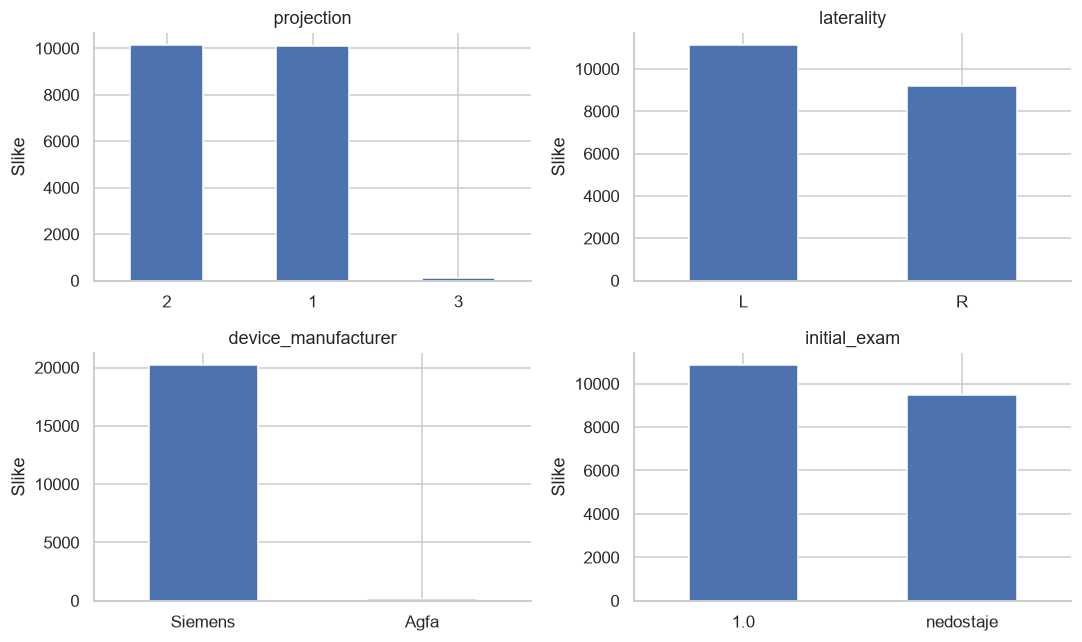

pixel_spacing,0.143,0.144
device_manufacturer,,
Agfa,112,0
Siemens,0,20215


**Numerički sažetak**

,vrednost
CSV_redovi,20327
projekcije,3
proizvođači,2
najmanja_grupa_proizvođača,112
vrednosti_pixel_spacing,2


In [5]:
cols = ['projection', 'laterality', 'device_manufacturer', 'initial_exam']
fig, axes = plt.subplots(2, 2, figsize=(10, 6))
for ax, col in zip(axes.flat, cols):
    counts = metadata[col].astype('string').fillna('nedostaje').value_counts()
    display(counts.rename('slike').to_frame())
    counts.plot.bar(ax=ax, rot=0)
    ax.set(title=col, xlabel='', ylabel='Slike')
plot(fig)
display(pd.crosstab(metadata.device_manufacturer, metadata.pixel_spacing, dropna=False))
summary(CSV_redovi=len(metadata), projekcije=metadata.projection.nunique(),
        proizvođači=metadata.device_manufacturer.nunique(),
        najmanja_grupa_proizvođača=int(metadata.device_manufacturer.value_counts().min()),
        vrednosti_pixel_spacing=metadata.pixel_spacing.nunique())

### Zaključak

Projekcije 1 i 2 gotovo su ravnomerno zastupljene, dok je projekcija 3 prisutna na svega 93 snimka. Snimci levog ručnog zgloba nešto su zastupljeniji od snimaka desnog.

Izražen disbalans uočava se kod proizvođača uređaja, gde je preko 99% snimaka nastalo na Siemens uređajima. Takođe, vrednost atributa `pixel_spacing` direktno je povezana sa proizvođačem uređaja.

Neravnomerna zastupljenost proizvođača i projekcija predstavlja potencijalno ograničenje generalizacije modela na snimke dobijene drugim uređajima ili iz manje zastupljenih projekcija.

## 6. Kliničke oznake

**Istraživačko pitanje.** Koje su kliničke vrednosti upisane i koliko oznaka nedostaje?

**Postupak.** Prikazujemo izvorne vrednosti po slici. Za AO prikazujemo najčešće zapisane kombinacije bez rastavljanja kodova.

,missing,percent
fracture_visible,6777,33.3399
diagnosis_uncertain,19790,97.3582
ao_classification,6169,30.3488
cast,14551,71.5846
osteopenia,17854,87.8339
metal,19619,96.5169


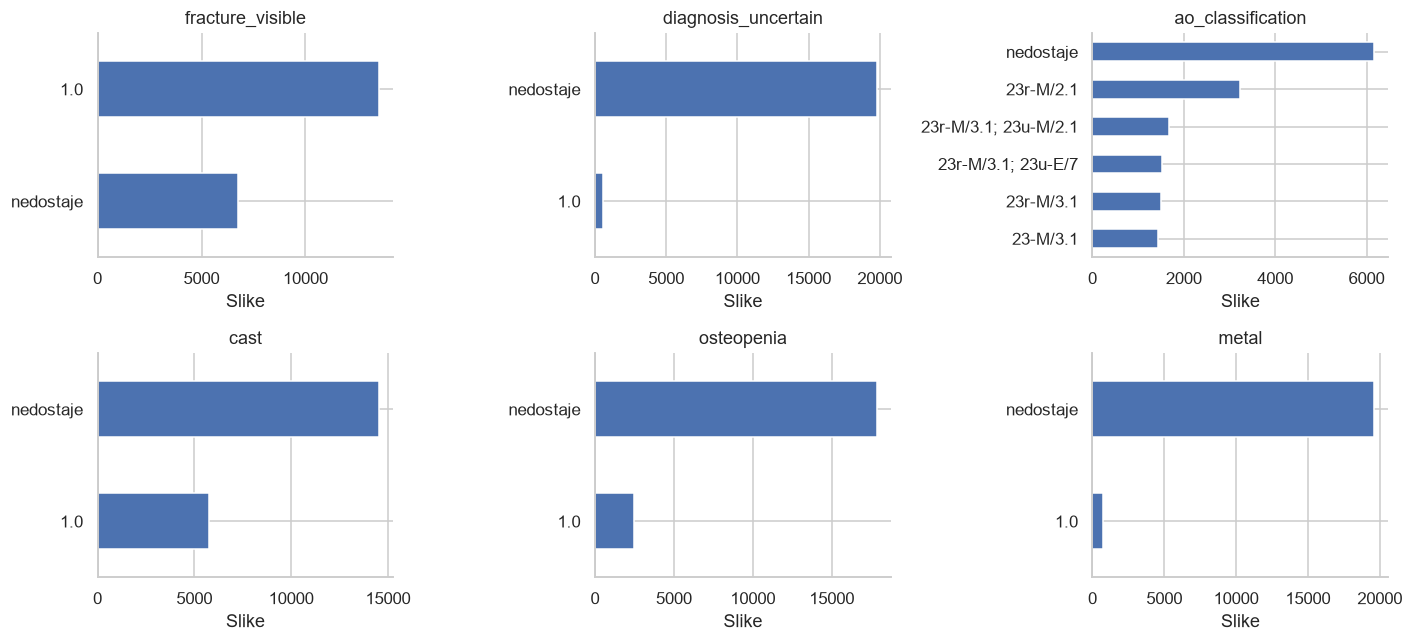

,slike
ao_classification,
NaN,6169
23r-M/2.1,3221
23r-M/3.1; 23u-M/2.1,1683
23r-M/3.1; 23u-E/7,1529
23r-M/3.1,1501
23-M/3.1,1436
23-M/2.1,1377
23r-E/2.1; 23u-E/7,630
23r-E/2.1,539


**Numerički sažetak**

,vrednost
CSV_redovi,20327
upisan_fracture_visible,13550
upisan_diagnosis_uncertain,537
različite_AO_kombinacije,107


In [6]:
clinical = ['fracture_visible', 'diagnosis_uncertain', 'ao_classification', 'cast', 'osteopenia', 'metal']
display(missing.loc[clinical])
fig, axes = plt.subplots(2, 3, figsize=(13, 6))
for ax, col in zip(axes.flat, clinical):
    counts = metadata[col].astype('string').fillna('nedostaje').value_counts()
    counts.head(6).sort_values().plot.barh(ax=ax)
    ax.set(title=col, xlabel='Slike', ylabel='')
plot(fig)
display(metadata.ao_classification.value_counts(dropna=False).head(12).rename('slike').to_frame())
summary(CSV_redovi=len(metadata), upisan_fracture_visible=int(metadata.fracture_visible.count()),
        upisan_diagnosis_uncertain=int(metadata.diagnosis_uncertain.count()),
        različite_AO_kombinacije=metadata.ao_classification.nunique())

### Zaključak

Vidljiv prelom evidentiran je na 13.550 snimaka (66,66%), dok je nesigurna dijagnoza zabeležena na svega 537 snimaka. AO klasifikacija obuhvata 107 različitih kombinacija, što ukazuje na raznovrsnost evidentiranih tipova preloma.

Prisustvo gipsa, osteopenije i metalnih elemenata može uticati na vizuelne karakteristike snimaka i otežati detekciju preloma.

Nedostajuće vrednosti u medicinskim atributima ne treba automatski tretirati kao negativne vrednosti. Za određivanje prisustva i lokalizacije preloma koristićemo odgovarajuće YOLO anotacije, dok će medicinski metapodaci služiti za dodatnu analizu i interpretaciju rezultata.

## 7. YOLO klase i broj objekata

**Istraživačko pitanje.** Koje klase postoje i kako su objekti raspoređeni po slici?

**Postupak.** Brojimo sve validne YOLO box-ove po originalnoj klasi. Broj objekata po slici računamo nad jednoznačnim, validno parsiranim anotacijama, uključujući prazne fajlove.

,klasa,objekti,slike
class_id,,,
0,boneanomaly,276,192
1,bonelesion,45,42
2,foreignbody,8,8
3,fracture,18090,13550
4,metal,818,707
5,periostealreaction,3453,2235
6,pronatorsign,567,566
7,softtissue,464,439
8,text,23722,20274


,objekti po slici
count,20327.0000
mean,2.3340
std,1.1897
min,0.0000
25%,1.0000
50%,2.0000
75%,3.0000
max,10.0000


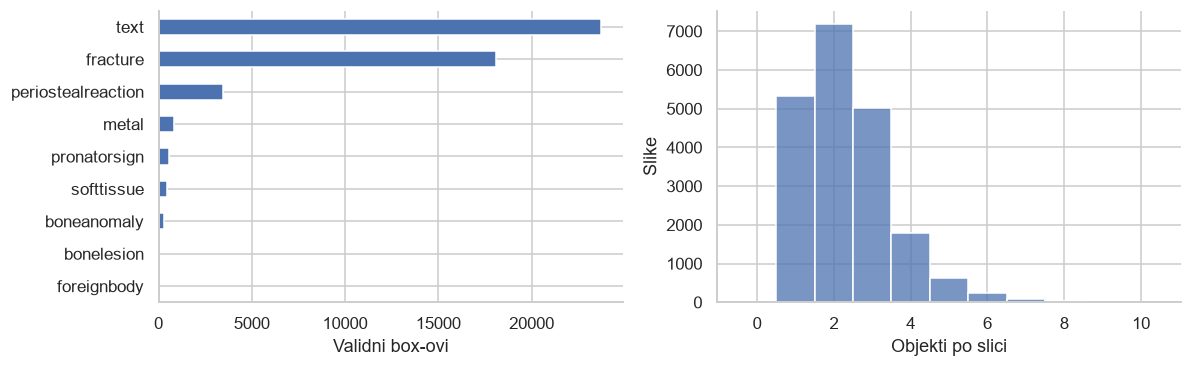

**Numerički sažetak**

,vrednost
YOLO_fajlovi,20327
klase,9
validni_objekti,47443
slike_sa_poznatim_brojem_objekata,20327
slike_sa_nula_objekata,15


In [7]:
classes = pd.Series(audit.classes, name='klasa').rename_axis('class_id').to_frame()
classes = classes.join(valid_boxes.groupby('class_id').filestem.agg(objekti='size', slike='nunique'))
classes[['objekti', 'slike']] = classes[['objekti', 'slike']].fillna(0).astype(int)
display(classes)
per_image = linked.loc[linked.annotation_state.isin(['valid', 'empty']), 'valid_boxes']
display(per_image.describe().to_frame('objekti po slici'))
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
classes.set_index('klasa').objekti.sort_values().plot.barh(ax=axes[0])
axes[0].set(xlabel='Validni box-ovi', ylabel='')
sns.histplot(per_image, discrete=True, ax=axes[1])
axes[1].set(xlabel='Objekti po slici', ylabel='Slike')
plot(fig)
summary(YOLO_fajlovi=len(audit.files), klase=len(classes), validni_objekti=len(valid_boxes),
        slike_sa_poznatim_brojem_objekata=len(per_image), slike_sa_nula_objekata=int(per_image.eq(0).sum()))

### Zaključak

Skup podataka sadrži 47.443 validno anotirana objekta raspoređena u 9 klasa. Najzastupljenije klase su `text` i `fracture`, dok su ostale klase znatno manje zastupljene, što ukazuje na izražen klasni disbalans.

Prosečan broj objekata po slici iznosi 2,33, pri čemu većina snimaka sadrži između 1 i 3 objekta. Maksimalan broj objekata po slici je 10, dok 15 snimaka ne sadrži nijedan anotirani objekat.

S obzirom na to da je cilj projekta isključivo detekcija preloma, u narednoj fazi analize fokusiraćemo se na klasu `fracture`, njenu zastupljenost i karakteristike pripadajućih bounding box-ova.

## 8. Veze izvora i integritet

**Istraživačko pitanje.** Da li CSV, slike i anotacije opisuju iste identifikatore?

**Postupak.** Poredimo skupove identifikatora i zasebno brojimo dvosmislene, prazne i nevalidne anotacije. Prefiks identifikatora proveravamo samo za odgovarajući obrazac. Pri tom poređenju numerički identifikator pacijenta formatiramo na četiri mesta, kao u inspektoru. Sirove vrednosti ostaju sačuvane.

In [8]:
annotation_ids = set(audit.files.filestem)
coverage = {
    'CSV bez slike': len(expected - indexed), 'slika bez CSV-a': len(indexed - expected),
    'CSV bez anotacije': len(expected - annotation_ids),
    'anotacija bez CSV-a': len(annotation_ids - expected),
    'duplirani slikovni redovi': int(index.filestem.duplicated(keep=False).sum()),
    'duplirani anotacioni redovi': int(audit.files.filestem.duplicated(keep=False).sum()),
}
display(linked.annotation_state.value_counts().rename('CSV redovi').to_frame())
display(index_issues, audit.issues.head(15))
from wrist_fracture.data.inspect_dataset import FILENAME_PATTERN

prefix = metadata.filestem.str.extract(FILENAME_PATTERN, expand=False)
patient_id = metadata.patient_id
comparable_id = patient_id.mask(patient_id.str.isdigit().fillna(False), patient_id.str.zfill(4))
mismatch = prefix.notna() & comparable_id.notna() & prefix.ne(comparable_id).fillna(False)
display(metadata.loc[prefix.isna() | mismatch, ['filestem', 'patient_id']].head(15))
summary(**coverage, YOLO_nevalidni_redovi=int(audit.files.invalid_rows.sum()),
        van_očekivanog_obrasca=int(prefix.isna().sum()), konflikti_prefiksa=int(mismatch.sum()))

,CSV redovi
annotation_state,
valid,20312
empty,15


,source,issue


,filestem,member,line,issue,raw


,filestem,patient_id
1342,0412_1230151360_01_WRI-R1_O016,412
1343,0412_1230151390_01_WRI-R2_O016,412


**Numerički sažetak**

,vrednost
CSV bez slike,0
slika bez CSV-a,0
CSV bez anotacije,0
anotacija bez CSV-a,0
duplirani slikovni redovi,0
duplirani anotacioni redovi,0
YOLO_nevalidni_redovi,0
van_očekivanog_obrasca,2
konflikti_prefiksa,0


### Zaključak

Utvrđena je potpuna usklađenost između CSV zapisa, snimaka i YOLO anotacija. Nisu pronađeni duplikati, nedostajući fajlovi niti nevalidni redovi anotacija.

Od ukupno 20.327 anotacionih fajlova, 20.312 sadrži validne anotacije, dok je 15 prazno. Dva identifikatora snimaka odstupaju od očekivanog obrasca imenovanja, ali nisu utvrđeni konflikti u identifikaciji pacijenata.

Rezultati ukazuju na visok nivo strukturne konzistentnosti skupa podataka, bez značajnih tehničkih prepreka za dalju obradu i pripremu podataka za treniranje.

## 9. Završni numerički pregled

**Istraživačko pitanje.** Koje brojke opisuju analizirane izvore?

**Postupak.** Objedinjujemo broj slike, pacijenta, anotacionog fajla i objekta iz prethodnih sekcija.

In [9]:
summary(CSV_redovi=len(metadata), pacijenti=len(per_patient), parovi_pacijent_study_number=study_pairs,
        jedinstvene_indeksirane_slike=len(indexed), anotacioni_fajlovi=len(audit.files),
        validni_objekti=len(valid_boxes), YOLO_klase=len(audit.classes), **coverage)

**Numerički sažetak**

,vrednost
CSV_redovi,20327
pacijenti,6091
parovi_pacijent_study_number,10699
jedinstvene_indeksirane_slike,20327
anotacioni_fajlovi,20327
validni_objekti,47443
YOLO_klase,9
CSV bez slike,0
slika bez CSV-a,0
CSV bez anotacije,0


### Završni zaključak

Početna eksplorativna analiza obuhvatila je strukturu, kvalitet, demografske i medicinske karakteristike skupa podataka, kao i distribuciju YOLO anotacija.

Skup sadrži 20.327 snimaka, 6.091 pacijenta i 47.443 validno anotirana objekta raspoređena u 9 klasa. Utvrđena je potpuna usklađenost između metapodataka, snimaka i anotacija.

Najvažnija zapažanja za nastavak projekta su:

- Neophodna je podela podataka na nivou pacijenata radi sprečavanja data leakage-a.
- Postoji neravnomerna zastupljenost uzrasnih grupa, polova, projekcija i proizvođača uređaja.
- Prisutan je izražen disbalans između anotiranih klasa.
- Nedostajuće vrednosti u medicinskim metapodacima ne predstavljaju direktnu prepreku za treniranje YOLO modela.

Skup podataka je strukturno konzistentan i pogodan za nastavak analize. Naredna faza obuhvata detaljnu analizu vizuelnih i tehničkih karakteristika snimaka, nakon koje sledi analiza usmerena isključivo na klasu `fracture`.